# 06 – Results

Comparison of all models on the same days and the same horizon (CLAUDE.md section 7). This notebook only **reads** the forecasts saved by notebooks 03 to 05 (`results/<name>.parquet` for the main test, `results/control/<name>.parquet` for the control period); it does not run any model.

| Family | Without covariates | With covariates (`load_fc`, `wind_fc`, `solar_fc`, `non_working_day`) |
|---|---|---|
| Baselines (`03_baselines`) | `naive_d1`, `naive_d7`, `naive_ref`, `holt_winters` | – |
| Classical (`04_sarima`) | `sarima` | `sarimax` |
| TimesFM 3 (`05_foundation`) | `timesfm` | `timesfm_cov` |
| Timestral-209M (`05_foundation`) | `timestral` | `timestral_cov` |

Sections:
1. Coverage check: every model forecasts exactly the same days and hours.
2. Metrics of all models: MAE, rMAE, RMSE, pinball loss, on the main test and on the control period.
3. The two-way table of the research question (family × covariates).
4. Forecast vs actual plots on a few representative days.
5. Contamination test: model cards and control period.
6. Diebold-Mariano tests: planned tests and pairwise p-value matrix.

The detailed error analyses come next in this notebook.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg
from src.data import load_dataset
from src.evaluation import RESULT_COLUMNS, mae, pinball, rmse

df = load_dataset()
CONTROL_DAYS = pd.date_range(cfg.CONTROL_START, cfg.CONTROL_END, freq="D")
PERIODS = {
    "main test": (cfg.TEST_DAYS, cfg.RESULTS_DIR),
    "control": (CONTROL_DAYS, cfg.RESULTS_DIR / "control"),
}

# Models in display order: name -> (label, family, uses covariates, probabilistic)
MODELS = {
    "naive_d1": ("Naive D−1", "Baseline", False, False),
    "naive_d7": ("Naive D−7", "Baseline", False, False),
    "naive_ref": ("Reference naive", "Baseline", False, False),
    "holt_winters": ("Holt-Winters", "Baseline", False, False),
    "sarima": ("SARIMA", "Classical", False, False),
    "sarimax": ("SARIMAX", "Classical", True, False),
    "timesfm": ("TimesFM 3", "TimesFM 3", False, True),
    "timesfm_cov": ("TimesFM 3 + cov.", "TimesFM 3", True, True),
    "timestral": ("Timestral", "Timestral", False, True),
    "timestral_cov": ("Timestral + cov.", "Timestral", True, True),
}
LABELS = {name: m[0] for name, m in MODELS.items()}
PROBABILISTIC = [name for name, m in MODELS.items() if m[3]]
# One hue per family; the version with covariates is drawn solid, the one without dashed
FAMILY_COLORS = {"Baseline": "C7", "Classical": "C0", "TimesFM 3": "C1", "Timestral": "C2"}
# Two-way table: family -> (model without covariates, model with covariates)
TWO_WAY = {
    "Classical (SARIMA / SARIMAX)": ("sarima", "sarimax"),
    "TimesFM 3": ("timesfm", "timesfm_cov"),
    "Timestral": ("timestral", "timestral_cov"),
}

res = {
    period: {name: pd.read_parquet(results_dir / f"{name}.parquet") for name in MODELS}
    for period, (days, results_dir) in PERIODS.items()
}
print(f"Dataset: {df.index[0]} → {df.index[-1]}")
for period, (days, _) in PERIODS.items():
    print(f"{period}: {len(days)} days ({days[0].date()} → {days[-1].date()}), {len(res[period])} models loaded")

Dataset: 2023-01-01 00:00:00 → 2026-11-08 23:00:00
main test: 183 days (2026-04-01 → 2026-09-30), 10 models loaded
control: 24 days (2026-10-16 → 2026-11-08), 10 models loaded


## 1. Coverage check

All models must be compared on the same days, the same hours and the same actual prices. For each period and each model, the check below verifies that the result file:

- has the common column layout (`model`, `target_date`, `hour`, `y_true`, `y_pred`, `q10` … `q90`);
- covers exactly the days of the period, with the 24 hours 0 … 23 of each day once (main test: 183 × 24 = 4,392 rows; control: 24 × 24 = 576 rows);
- has finite point forecasts, and complete quantiles if and only if the model is probabilistic (TimesFM 3, Timestral);
- has the same `y_true` as the dataset (actual day-ahead price of each hour).

In [ ]:
def coverage(r: pd.DataFrame, name: str, days: pd.DatetimeIndex) -> dict:
    expected = pd.MultiIndex.from_product([days, range(cfg.HORIZON)], names=["target_date", "hour"])
    keys = pd.MultiIndex.from_frame(r[["target_date", "hour"]])
    actual = df.loc[r["target_date"] + pd.to_timedelta(r["hour"], unit="h"), cfg.TARGET].to_numpy()
    quantiles_present = r[cfg.QUANTILE_COLUMNS].notna().all(axis=1)
    return {
        "rows": len(r),
        "days": r["target_date"].nunique(),
        "columns OK": list(r.columns) == RESULT_COLUMNS and (r["model"] == name).all(),
        "days × hours OK": keys.is_unique and keys.sort_values().equals(expected),
        "y_pred finite": bool(np.isfinite(r["y_pred"]).all()),
        "quantiles": "all" if quantiles_present.all() else ("none" if not quantiles_present.any() else "partial"),
        "y_true = dataset": bool(np.array_equal(r["y_true"].to_numpy(), actual)),
    }


check = pd.concat({
    period: pd.DataFrame({name: coverage(r, name, PERIODS[period][0]) for name, r in models.items()}).T
    for period, models in res.items()
})
display(check)

for (period, name), row in check.iterrows():
    n_days = len(PERIODS[period][0])
    assert row["rows"] == n_days * cfg.HORIZON and row["days"] == n_days, (period, name)
    assert row["columns OK"] and row["days × hours OK"] and row["y_pred finite"] and row["y_true = dataset"], (period, name)
    assert row["quantiles"] == ("all" if name in PROBABILISTIC else "none"), (period, name)
print("All result files cover the same days and hours, with the same actual prices.")

rows days columns OK days × hours OK y_pred finite  \
main test naive_d1       4392  183       True            True          True   
          naive_d7       4392  183       True            True          True   
          naive_ref      4392  183       True            True          True   
          holt_winters   4392  183       True            True          True   
          sarima         4392  183       True            True          True   
          sarimax        4392  183       True            True          True   
          timesfm        4392  183       True            True          True   
          timesfm_cov    4392  183       True            True          True   
          timestral      4392  183       True            True          True   
          timestral_cov  4392  183       True            True          True   
control   naive_d1        576   24       True            True          True   
          naive_d7        576   24       True            True          True   
          naive_ref       576   24       True            True          True   
          holt_winters    576   24       True            True          True   
          sarima          576   24       True            True          True   
          sarimax         576   24       True            True          True   
          timesfm         576   24       True            True          True   
          timesfm_cov     576   24       True            True          True   
          timestral       576   24       True            True          True   
          timestral_cov   576   24       True            True          True   

                        quantiles y_true = dataset  
main test naive_d1           none             True  
          naive_d7           none             True  
          naive_ref          none             True  
          holt_winters       none             True  
          sarima             none             True  
          sarimax            none             True  
          timesfm             all             True  
          timesfm_cov         all             True  
          timestral           all             True  
          timestral_cov       all             True  
control   naive_d1           none             True  
          naive_d7           none             True  
          naive_ref          none             True  
          holt_winters       none             True  
          sarima             none             True  
          sarimax            none             True  
          timesfm             all             True  
          timesfm_cov         all             True  
          timestral           all             True  
          timestral_cov       all             True

All result files cover the same days and hours, with the same actual prices.


All 10 models × 2 periods pass: **4,392 forecasts per model on the main test, 576 on the control period**, on the same (day, hour) pairs and against the same actual prices. Every comparison below is therefore paired.

To compare rows in long format directly, the results are also sorted the same way (by day, then hour) and stacked into one table per period.

In [ ]:
for period, models in res.items():
    for name, r in models.items():
        models[name] = r.sort_values(["target_date", "hour"], ignore_index=True)
    first = next(iter(models.values()))
    for r in models.values():
        assert r[["target_date", "hour", "y_true"]].equals(first[["target_date", "hour", "y_true"]])

long = {period: pd.concat(models.values(), ignore_index=True) for period, models in res.items()}
long["main test"].head(3)

,model,target_date,hour,y_true,y_pred,q10,q20,q30,q40,q50,q60,q70,q80,q90
0,naive_d1,2026-04-01,0,145.5100,109.245,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,naive_d1,2026-04-01,1,129.4875,102.680,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,naive_d1,2026-04-01,2,125.3450,101.260,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Metrics of all models

For each model and period, in EUR/MWh except rMAE:

- **MAE** (main metric) and **RMSE** of the point forecast (the median for the foundation models);
- **rMAE** = MAE / MAE of the reference naive (`naive_ref`) on the same days: below 1, better than the naive;
- **pinball loss** averaged over the 9 levels 0.1 … 0.9 and over the hours, for the probabilistic models only (TimesFM 3 and Timestral provide these exact levels, see `05_foundation.ipynb`). It is in EUR/MWh like the MAE: the pinball loss of the 0.5 quantile is half its absolute error.

In [ ]:
def metrics(models: dict) -> pd.DataFrame:
    ref_mae = mae(models["naive_ref"]["y_true"], models["naive_ref"]["y_pred"])
    rows = {}
    for name, r in models.items():
        m = mae(r["y_true"], r["y_pred"])
        rows[name] = {
            "MAE": m,
            "rMAE": m / ref_mae,
            "RMSE": rmse(r["y_true"], r["y_pred"]),
            "pinball": pinball(r["y_true"], r[cfg.QUANTILE_COLUMNS]) if name in PROBABILISTIC else np.nan,
        }
    return pd.DataFrame(rows).T


table = pd.concat({period: metrics(models) for period, models in res.items()}, axis=1)
table.index = [LABELS[name] for name in table.index]
table.style.format("{:.2f}", na_rep="–").format("{:.3f}", subset=[(p, "rMAE") for p in PERIODS])

In [ ]:
# Ranking by MAE on the main test
ranking = table["main test"].sort_values("MAE")
ranking.insert(0, "rank", range(1, len(ranking) + 1))
ranking.round(3)

,rank,MAE,rMAE,RMSE,pinball
Timestral + cov.,1,13.047,0.372,26.401,5.215
TimesFM 3 + cov.,2,14.438,0.412,28.703,5.826
SARIMAX,3,17.878,0.510,31.218,NaN
Timestral,4,22.761,0.649,39.695,9.022
TimesFM 3,5,24.256,0.692,40.741,9.718
Holt-Winters,6,28.153,0.803,45.037,NaN
SARIMA,7,29.382,0.838,45.642,NaN
Naive D−1,8,33.040,0.943,53.696,NaN
Reference naive,9,35.049,1.000,56.978,NaN
Naive D−7,10,41.695,1.190,65.075,NaN


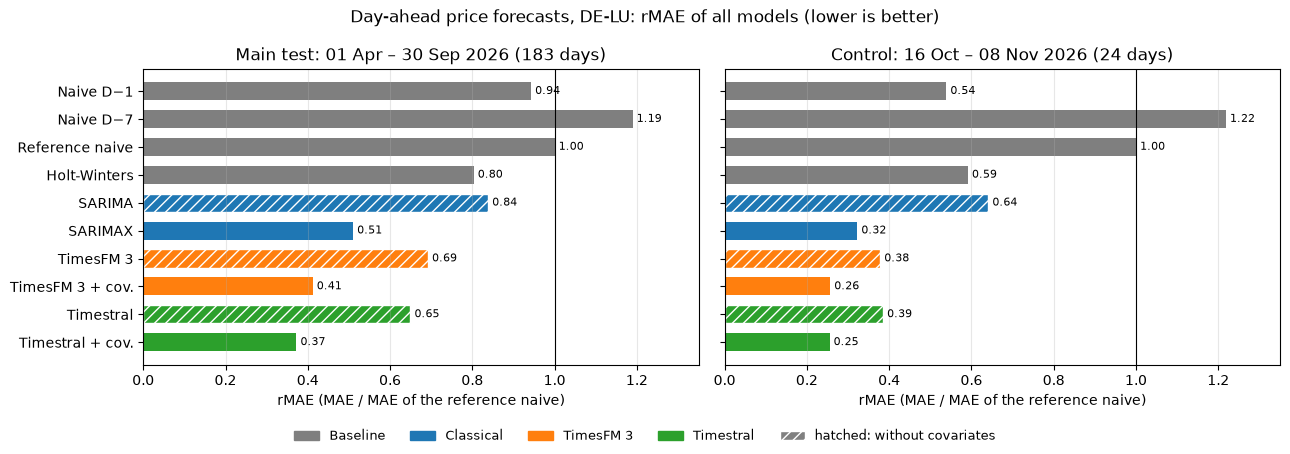

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
order = list(MODELS)[::-1]  # barh draws from the bottom: reversed so that the naives are at the top
for ax, period in zip(axes, PERIODS):
    rmae = table[(period, "rMAE")].reindex([LABELS[n] for n in order])
    colors = [FAMILY_COLORS[MODELS[n][1]] for n in order]
    bars = ax.barh(rmae.index, rmae.to_numpy(), color=colors, height=0.65)
    for bar, name in zip(bars, order):
        if MODELS[name][1] != "Baseline" and not MODELS[name][2]:
            bar.set_hatch("///")  # no covariates
            bar.set_edgecolor("white")
    for y, v in enumerate(rmae):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8)
    ax.axvline(1, color="k", lw=0.8)
    ax.set_xlim(0, 1.35)
    ax.set_xlabel("rMAE (MAE / MAE of the reference naive)")
    days = PERIODS[period][0]
    ax.set_title(f"{period.capitalize()}: {days[0]:%d %b} – {days[-1]:%d %b %Y} ({len(days)} days)")
    ax.grid(axis="x", alpha=0.3)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
handles.append(plt.Rectangle((0, 0), 1, 1, facecolor="grey", hatch="///", edgecolor="white"))
fig.legend(handles, [*FAMILY_COLORS, "hatched: without covariates"], loc="lower center", ncol=5, fontsize=9,
           frameon=False)
fig.suptitle("Day-ahead price forecasts, DE-LU: rMAE of all models (lower is better)")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(cfg.FIGURES_DIR / "results_rmae_all_models.png", dpi=150)
plt.show()

**Observations (main test).**
- **The three models with covariates come first**: Timestral + cov. (MAE 13.0 EUR/MWh, rMAE 0.37), TimesFM 3 + cov. (14.4, 0.41), SARIMAX (17.9, 0.51). Each of them beats every model without covariates.
- **Without covariates, the foundation models are the best**: Timestral (22.8, rMAE 0.65) and TimesFM 3 (24.3, 0.69) are ahead of Holt-Winters (28.2) and SARIMA (29.4), but far behind SARIMAX.
- **RMSE gives the same order.** RMSE is about 1.6 to 2 times the MAE for every model: the errors are heavy-tailed (price spikes, deep negative hours), see section 4.
- **Pinball loss**: Timestral + cov. 5.2, TimesFM 3 + cov. 5.8 EUR/MWh. The covariates reduce it by about 40 % for both models, as they reduce the MAE.

**Control period** (24 days, 16 October – 8 November 2026). The rMAE of every model is lower, because the reference naive is much worse there (MAE 73.3 against 35.0): 11 of the 24 days are forecast with D−7, which works badly in autumn, when the price level moves from week to week (`naive_d1` has rMAE 0.54). The MAE is the easier number to compare across periods: it increases for all models from the main test to the control period (e.g. SARIMAX 17.9 → 23.6, Timestral + cov. 13.0 → 18.7). The order is the same as on the main test, except that TimesFM 3 and Timestral are now close in both versions (27.7 vs 28.2 without covariates, 18.8 vs 18.7 with). With 24 days, differences of 1 or 2 EUR/MWh are not meaningful without a test. The contamination test (section 5) and the Diebold-Mariano tests (section 6) follow.

## 3. The two-way table

The research question (CLAUDE.md section 3) as a family × covariates table. A **row** gives the contribution of the covariates within a family; a **column** compares families with the same information (prices only, or prices + the same four known-future covariates). The covariate gain is the relative MAE reduction from the version without to the version with covariates.

In [ ]:
def two_way(period: str) -> pd.DataFrame:
    t = table[period]
    rows = {}
    for family, (without, with_cov) in TWO_WAY.items():
        a, b = t.loc[LABELS[without]], t.loc[LABELS[with_cov]]
        rows[family] = {
            ("MAE", "without cov."): a["MAE"], ("MAE", "with cov."): b["MAE"],
            ("rMAE", "without cov."): a["rMAE"], ("rMAE", "with cov."): b["rMAE"],
            ("covariate gain [%]", "MAE"): 100 * (1 - b["MAE"] / a["MAE"]),
        }
    return pd.DataFrame(rows).T


two_way_table = pd.concat({period: two_way(period) for period in PERIODS})
fmt = {c: "{:.3f}" if c[0] == "rMAE" else ("{:.0f} %" if c[0].startswith("covariate") else "{:.2f}")
       for c in two_way_table.columns}
display(two_way_table.style.format(fmt))
for period in PERIODS:
    t = table[period]
    print(f"{period}: reference naive MAE {t.loc['Reference naive', 'MAE']:.2f}, "
          f"Holt-Winters MAE {t.loc['Holt-Winters', 'MAE']:.2f} EUR/MWh")

main test: reference naive MAE 35.05, Holt-Winters MAE 28.15 EUR/MWh
control: reference naive MAE 73.29, Holt-Winters MAE 43.34 EUR/MWh


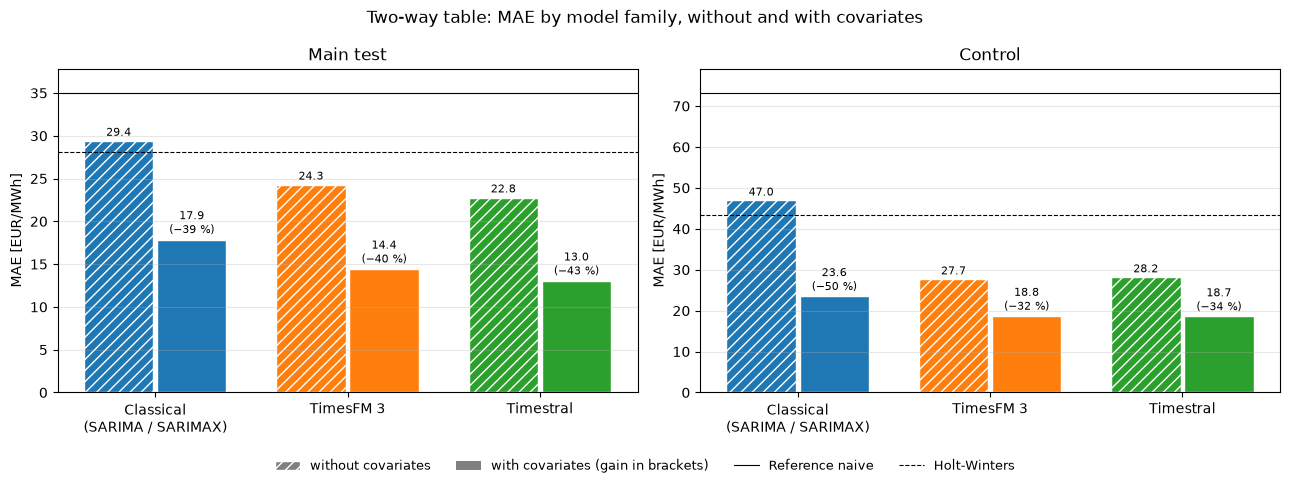

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
width = 0.38
for ax, period in zip(axes, PERIODS):
    t = two_way_table.loc[period]
    x = np.arange(len(t))
    colors = [FAMILY_COLORS[MODELS[TWO_WAY[f][1]][1]] for f in t.index]
    for k, (col, hatch) in enumerate([("without cov.", "///"), ("with cov.", None)]):
        values = t[("MAE", col)].to_numpy()
        positions = x + (k - 0.5) * width
        ax.bar(positions, values, width * 0.95, color=colors, hatch=hatch, edgecolor="white")
        for xi, v, gain in zip(positions, values, t[("covariate gain [%]", "MAE")]):
            label = f"{v:.1f}" if k == 0 else f"{v:.1f}\n(−{gain:.0f} %)"
            ax.text(xi, v + 0.01 * ax.get_ylim()[1], label, ha="center", va="bottom", fontsize=8)
    for name, ls in [("Reference naive", "-"), ("Holt-Winters", "--")]:
        ax.axhline(table.loc[name, (period, "MAE")], color="k", lw=0.8, ls=ls)
    ax.set_ylim(0, 1.08 * table.loc["Reference naive", (period, "MAE")])
    ax.set_xticks(x, ["Classical\n(SARIMA / SARIMAX)", "TimesFM 3", "Timestral"])
    ax.set_ylabel("MAE [EUR/MWh]")
    ax.set_title(period.capitalize())
    ax.grid(axis="y", alpha=0.3)
handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor="grey", hatch="///", edgecolor="white"),
    plt.Rectangle((0, 0), 1, 1, facecolor="grey"),
    plt.Line2D([], [], color="k", lw=0.8, ls="-"),
    plt.Line2D([], [], color="k", lw=0.8, ls="--"),
]
fig.legend(handles, ["without covariates", "with covariates (gain in brackets)", "Reference naive", "Holt-Winters"],
           loc="lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Two-way table: MAE by model family, without and with covariates")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(cfg.FIGURES_DIR / "results_two_way_mae.png", dpi=150)
plt.show()

**Reading the rows: the contribution of the covariates.** On the main test, the covariates reduce the MAE by about **40 % in every family** (classical 39 %, TimesFM 3 40 %, Timestral 43 %). The relative gain does not depend much on the family. In absolute terms, SARIMA gains the most (−11.5 EUR/MWh), because it starts from the highest error. On the control period, the gain is larger for the classical family (50 %) than for the foundation models (32–34 %).

**Reading the columns: classical vs foundation models with the same information.**
- Prices only: TimesFM 3 and Timestral reduce the MAE of SARIMA by 17 % and 22 %.
- With the same four covariates: TimesFM 3 + cov. and Timestral + cov. reduce the MAE of SARIMAX by 19 % and 27 %.

The foundation models used zero-shot are therefore ahead of the course models in both columns, with Timestral slightly ahead of TimesFM 3 on the main test (by about 1.5 EUR/MWh in both columns).

**Across the diagonal**: SARIMAX (17.9) is much better than the univariate foundation models (22.8 and 24.3). On this task, adding the covariate forecasts to a course model brings more than replacing it with a foundation model that only sees the prices. The best result combines both.

Whether these differences are significant is tested with the Diebold-Mariano test in section 6.

## 4. Forecasts vs actual prices on representative days

Three days of the main test, chosen by a fixed rule on the **actual** prices (for illustration only: nothing here feeds back into a model):

- **calm day**: the day with the lowest standard deviation of its 24 prices;
- **spike**: the day with the highest hourly price;
- **negative prices**: the day with the most hours below 0 EUR/MWh (ties broken by the lowest mean price).

For each day, one panel per family: the version without covariates (dashed) and with covariates (solid), and for the foundation models the 10–90 % band of each version (q10 … q90). The reference naive is drawn in grey in every panel for scale.

In [ ]:
main = res["main test"]
actual = main["naive_ref"].assign(t=lambda r: r["target_date"] + pd.to_timedelta(r["hour"], unit="h"))
daily = actual.groupby("target_date")["y_true"].agg(
    std="std", min="min", max="max", mean="mean", negative_hours=lambda s: int((s < 0).sum()))

examples = {
    "calm day": daily["std"].idxmin(),
    "spike": daily["max"].idxmax(),
    "negative prices": daily.sort_values(["negative_hours", "mean"], ascending=[False, True]).index[0],
}
info = daily.loc[list(examples.values())].round(1)
info.insert(0, "example", list(examples))
info.insert(1, "weekday", info.index.day_name())
info["non_working_day"] = df.loc[info.index, "non_working_day"].to_numpy()
info["mean wind_fc [GW]"] = [df.loc[d : d + pd.Timedelta(hours=23), "wind_fc"].mean().round(1) for d in info.index]
info["mean solar_fc [GW]"] = [df.loc[d : d + pd.Timedelta(hours=23), "solar_fc"].mean().round(1) for d in info.index]
info

,example,weekday,std,min,max,mean,negative_hours,non_working_day,mean wind_fc [GW],mean solar_fc [GW]
target_date,,,,,,,,,,
2026-05-11,calm day,Monday,15.6,96.0,154.0,119.3,0,0,16.8,7.5
2026-09-14,spike,Monday,126.1,161.4,697.3,256.5,0,0,3.2,10.4
2026-04-05,negative prices,Sunday,40.4,-105.2,33.4,-16.3,18,1,39.5,11.1


In [ ]:
def day_mae(name: str, day: pd.Timestamp) -> float:
    r = main[name][main[name]["target_date"] == day]
    return mae(r["y_true"], r["y_pred"])


day_table = pd.DataFrame({
    f"{example} ({day:%a %d %b})": {LABELS[name]: day_mae(name, day) for name in MODELS}
    for example, day in examples.items()
})
day_table.round(1).rename_axis("MAE [EUR/MWh]")

,calm day (Mon 11 May),spike (Mon 14 Sep),negative prices (Sun 05 Apr)
MAE [EUR/MWh],,,
Naive D−1,48.5,90.4,49.4
Naive D−7,26.8,100.7,86.7
Reference naive,26.8,100.7,86.7
Holt-Winters,26.4,83.8,39.1
SARIMA,38.5,110.3,75.6
SARIMAX,14.3,52.8,15.8
TimesFM 3,22.2,74.5,60.0
TimesFM 3 + cov.,13.7,47.4,23.8
Timestral,30.4,61.6,50.5


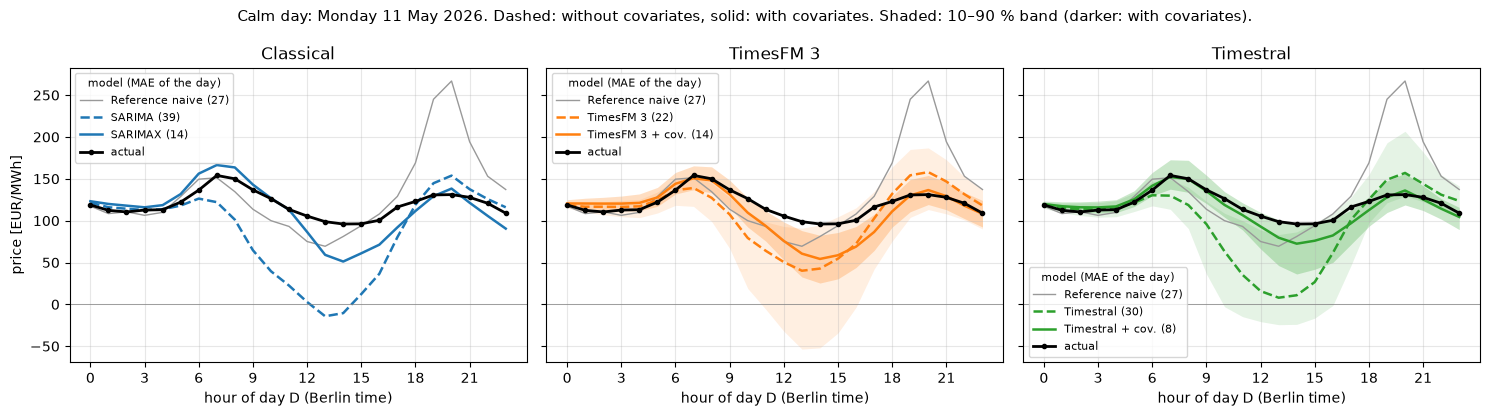

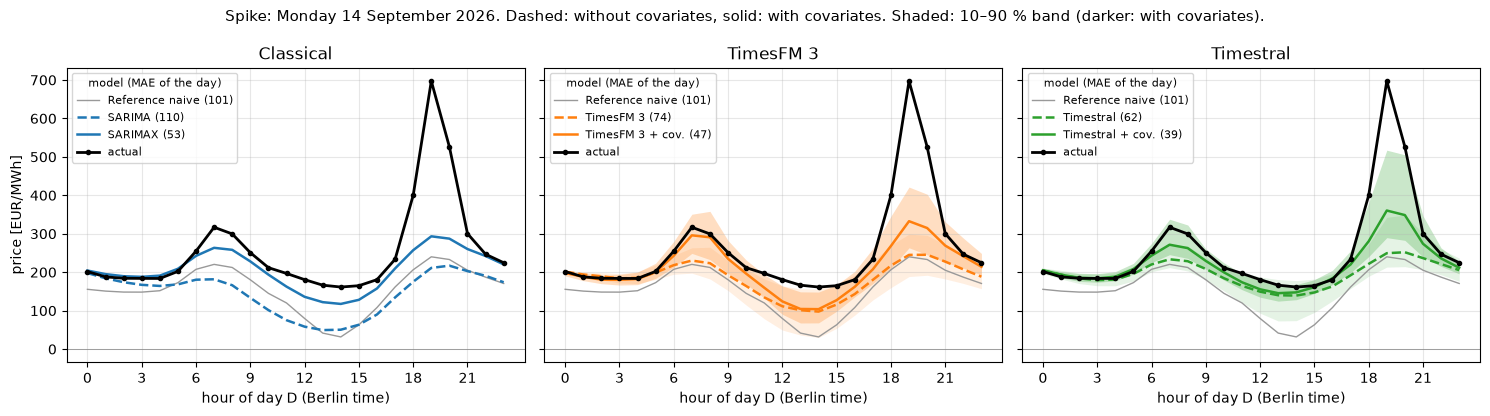

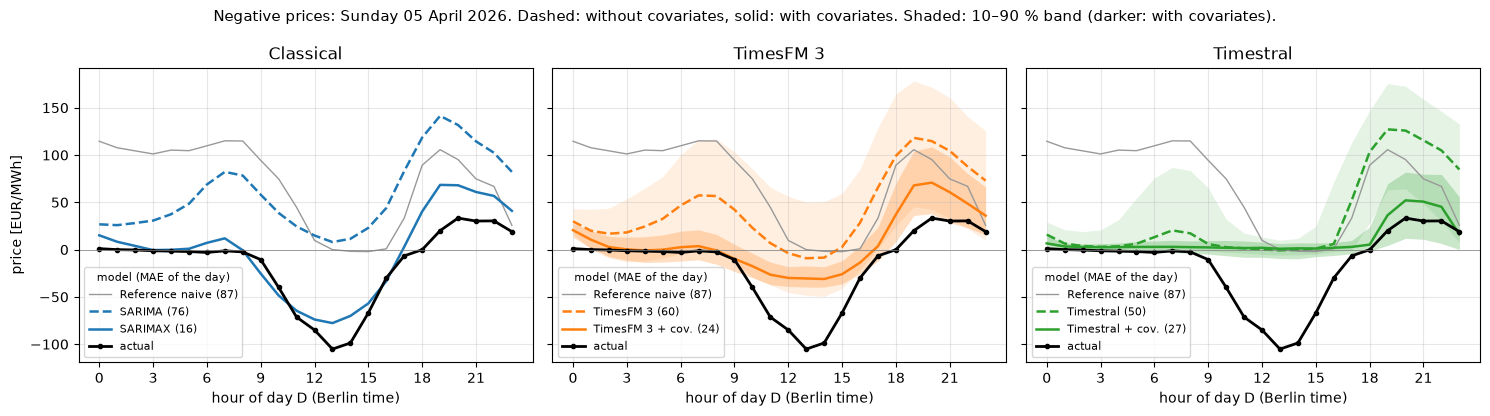

In [ ]:
PANELS = [("Classical", "sarima", "sarimax"), ("TimesFM 3", "timesfm", "timesfm_cov"),
          ("Timestral", "timestral", "timestral_cov")]
hours = np.arange(cfg.HORIZON)

for example, day in examples.items():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
    y_true = main["naive_ref"].loc[main["naive_ref"]["target_date"] == day, "y_true"].to_numpy()
    for ax, (family, without, with_cov) in zip(axes, PANELS):
        color = FAMILY_COLORS[family]
        ref = main["naive_ref"][main["naive_ref"]["target_date"] == day]
        ax.plot(hours, ref["y_pred"], color="0.6", lw=1, label=f"{LABELS['naive_ref']} ({day_mae('naive_ref', day):.0f})")
        for name, ls, alpha in [(without, "--", 0.12), (with_cov, "-", 0.25)]:
            r = main[name][main[name]["target_date"] == day]
            if name in PROBABILISTIC:
                ax.fill_between(hours, r["q10"], r["q90"], color=color, alpha=alpha, lw=0)
            ax.plot(hours, r["y_pred"], color=color, ls=ls, lw=1.8, label=f"{LABELS[name]} ({day_mae(name, day):.0f})")
        ax.plot(hours, y_true, color="k", lw=2, marker="o", ms=3, label="actual")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_xticks(range(0, 24, 3))
        ax.set_xlabel("hour of day D (Berlin time)")
        ax.set_title(family)
        ax.legend(fontsize=8, title="model (MAE of the day)", title_fontsize=8, loc="best")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("price [EUR/MWh]")
    bands = " Shaded: 10–90 % band (darker: with covariates)."
    fig.suptitle(f"{example.capitalize()}: {day:%A %d %B %Y}. Dashed: without covariates, solid: with covariates.{bands}",
                 fontsize=11)
    fig.tight_layout()
    fig.savefig(cfg.FIGURES_DIR / f"forecast_example_{example.replace(' ', '_')}.png", dpi=150)
    plt.show()

**Observations.**
- **Calm day** (Monday 11 May, the lowest intraday standard deviation of the test, 15.6 EUR/MWh). The main difficulty is the midday solar dip. The models without covariates forecast a deep dip, as on the previous days (SARIMA reaches −14 EUR/MWh at 13:00, Timestral univariate +8), while the actual price stays near 95. The reference naive copies the evening peak of the previous Monday (265 EUR/MWh), which does not happen. With the solar and wind forecasts, the dip becomes shallower, and Timestral + cov. follows the day closely (MAE 7.9).
- **Spike** (Monday 14 September, 697 EUR/MWh at 19:00, mean wind forecast 3.2 GW). No model reaches the spike. With covariates, all three models raise the evening peak (SARIMAX ≈ 290, TimesFM 3 + cov. ≈ 330, Timestral + cov. ≈ 360 EUR/MWh) and their error on the day is roughly halved. The 90 % quantile of Timestral + cov. goes up to ≈ 515 EUR/MWh: the band widens on the right hours but still misses the spike. Low wind is a necessary condition for such spikes, but the size of the spike also depends on gas prices and on the available capacity, which no model sees (CLAUDE.md section 10).
- **Negative prices** (Easter Sunday 5 April: 18 hours below 0, minimum −105 EUR/MWh, mean wind forecast 39.5 GW, the windiest day of the test). The models without covariates forecast an ordinary Sunday. **SARIMAX is the best model of the day** (MAE 15.8): its linear regression on wind and solar extrapolates down to −78 EUR/MWh. TimesFM 3 + cov. goes down to −31. Timestral + cov. stays at about 0 (lowest median +0.9, lowest q10 −10). This is not the non-negative clip, which is disabled (`clip_nonnegative=False`) and would not apply anyway, because the context contains negative prices. Over its 2,048 h context, the lowest price was only −11.8 EUR/MWh (47 negative hours), and the foundation models do not extrapolate much below the range of their context. Negative-price hours are analysed over the whole test in the detailed analyses.

## Summary so far

- All 10 models were evaluated on exactly the same 183 × 24 hours of the main test and 24 × 24 hours of the control period, against the same actual prices.
- **Covariates**: about −40 % MAE in every family on the main test (SARIMA → SARIMAX −39 %, TimesFM 3 −40 %, Timestral −43 %).
- **Foundation vs classical**: used zero-shot, TimesFM 3 and Timestral beat the course models in both columns of the table (−17 to −27 % MAE), and Timestral + cov. is the best model overall (MAE 13.0 EUR/MWh, rMAE 0.37). However, SARIMAX is better than the foundation models without covariates.
- **Failure cases**: no model forecasts the extreme evening spikes. On a deep negative-price day, the foundation models stay within the range of their context, while SARIMAX extrapolates through its regression on wind and solar.

Figures exported to `figures/`: `results_rmae_all_models.png`, `results_two_way_mae.png`, `forecast_example_calm_day.png`, `forecast_example_spike.png`, `forecast_example_negative_prices.png`.

## 5. Contamination test

TimesFM 3 (released 31 August 2026) and Timestral (released 15 October 2026) were published **during or after the main test** (1 April – 30 September 2026). If the DE-LU day-ahead prices of the test period were in their training data, their forecasts would partly be recall rather than forecasting, and the comparison with the classical models would be biased in their favour (CLAUDE.md section 7).

Two checks:
1. **Documentation**: what the model cards and papers say about the training data and its cutoff date.
2. **Control period** (16 October – 8 November 2026): posterior to the release of both models, so it cannot be in their training data. A foundation model that is **clearly better on the main test than on the control period, while the other models are stable**, would be a contamination signal.

### 5.1 What the model cards say

Read on 19 November 2026.

| | TimesFM 3 (`google/timesfm-3.0-pytorch`) | Timestral-209M (`mistralai/Timestral-209M`) |
|---|---|---|
| Release | 31 August 2026 | 15 October 2026 ([blog post](https://mistral.ai/news/timestral/)) |
| Training data described | Yes, as a list of sources ([model card](https://huggingface.co/google/timesfm-3.0-pytorch), section *Data*): GiftEvalPretrain excluding the datasets that overlap with fev-bench; Wikipedia pageviews; Google Trends top queries; synthetic and augmented data | Only in general terms ([tech report, arXiv:2610.37585](https://arxiv.org/abs/2610.37585), section 4.1; [blog post](https://mistral.ai/news/timestral/)): pre-trained **only on synthetic data** (context 8,192), then post-trained on "a mixture of real and synthetic data" (context 32,768) |
| Real datasets named | Yes (above) | **No**: the real post-training datasets are not listed in the model card, the README of the [GitHub repository](https://github.com/mistralai/timestral) or the tech report |
| Cutoff date | Wikipedia pageviews: November 2023; Google Trends: end of 2022; none given for GiftEvalPretrain | **Not stated** |
| Energy / electricity price data | [GiftEvalPretrain](https://huggingface.co/datasets/Salesforce/GiftEvalPretrain) (last modified January 2025) contains electricity **demand** datasets (`australian_electricity_demand`, `elecdemand`, `covid19_energy`) but no electricity price dataset, and nothing from 2026 | Not stated. "Energy" appears only as an application domain in the blog post |
| Statement on test-set overlap | Overlap with fev-bench removed (benchmark only, not about our data) | None for the public checkpoint (the blog post mentions control over training data only for Mistral's paid custom-training offer) |

The model card of TimesFM 3 cites the 2023 TimesFM paper ([arXiv:2310.10688](https://arxiv.org/abs/2310.10688)) and refers to "the paper" for details, but no TimesFM 3 paper is linked.

**Reading.**
- **TimesFM 3**: if its model card is complete, its training data **cannot contain DE-LU prices of 2026**: the only real sources are older than 2025 and none of them is an electricity price series. Moreover, its release (31 August) is before the last month of the main test, so September 2026 cannot be in its training data in any case.
- **Timestral**: the documentation does **not allow excluding** contamination. The real post-training data is not described and no cutoff date is given. DE-LU day-ahead prices are public (ENTSO-E, Energy-Charts) and the model was released two weeks after the end of the main test, so, in principle, the test prices could have been in the post-training mix. Only the empirical check below can say something.

### 5.2 Main test vs control period

The rMAE of the protocol is not a good tool to compare the two periods: its denominator, the reference naive, is much worse on the control period (MAE 35.0 → 73.3 EUR/MWh, because D−7 works badly in autumn, see section 2), so the rMAE of **every** model drops. The table below therefore shows, for each period, the MAE and three ratios, each against a different reference model computed on the same days:

- **rMAE** (reference naive): the protocol metric;
- **MAE / SARIMAX**: the best classical model, which sees the same information as the "+ cov." foundation models. It is not exposed to contamination (re-estimated on 8 weeks of data before each forecast);
- **MAE / naive D−1**: the simplest reference, which only depends on how much the price changes from one day to the next.

The column **control / main** divides the control value by the main test value. For the MAE, a value above 1 means the period is harder for that model. For the ratios, a value above 1 means that the model loses ground against the reference on the control period. Contamination would show as a foundation model whose control / main ratio is clearly **above** the one of the classical models.

In [ ]:
FOUNDATION = ["timesfm", "timesfm_cov", "timestral", "timestral_cov"]
# Scale-free comparisons across periods: column label -> reference model
REFERENCES = {"rMAE": "naive_ref", "MAE / SARIMAX": "sarimax", "MAE / naive D−1": "naive_d1"}


def abs_errors(period: str, name: str) -> pd.Series:
    """Absolute errors of a model over a period, indexed by target day (24 values per day)."""
    r = res[period][name]
    return (r["y_true"] - r["y_pred"]).abs().set_axis(r["target_date"])


contamination = {}
for name in MODELS:
    row = {("MAE", p): abs_errors(p, name).mean() for p in PERIODS}
    for label, ref in REFERENCES.items():
        if ref != name:
            row.update({(label, p): abs_errors(p, name).mean() / abs_errors(p, ref).mean() for p in PERIODS})
    for label in ["MAE", *REFERENCES]:
        if (label, "control") in row:
            row[(label, "control / main")] = row[(label, "control")] / row[(label, "main test")]
    contamination[LABELS[name]] = row
contamination = pd.DataFrame(contamination).T
contamination.columns = pd.MultiIndex.from_tuples(contamination.columns)
contamination = contamination[[(label, c) for label in ["MAE", *REFERENCES] for c in [*PERIODS, "control / main"]]]
contamination.style.format("{:.2f}", na_rep="–").format(
    "{:.3f}", subset=[c for c in contamination.columns if c[0] != "MAE" and c[1] != "control / main"])

With only 24 control days, a ratio can move by chance. To know how much, the ratio MAE / SARIMAX is **bootstrapped over days** (2,000 resamples of the days of each period, with replacement, the same days for the model and for SARIMAX, seed fixed). The 24 hours of a day are resampled together, because their errors are strongly correlated. The change control / main is computed from independent resamples of the two periods.

In [ ]:
N_BOOT = 2000
rng = np.random.default_rng(cfg.SEED)


def daily_mae(period: str, name: str) -> np.ndarray:
    return abs_errors(period, name).groupby(level=0).mean().to_numpy()


def bootstrap_ratio(period: str, name: str, ref: str) -> np.ndarray:
    """MAE(name) / MAE(ref) on N_BOOT resamples of the days of the period, paired (same days for both)."""
    a, b = daily_mae(period, name), daily_mae(period, ref)
    idx = rng.integers(0, len(a), size=(N_BOOT, len(a)))
    return a[idx].mean(axis=1) / b[idx].mean(axis=1)


def ci(x: np.ndarray) -> np.ndarray:
    return np.quantile(x, [0.025, 0.975])


boot_models = [n for n in MODELS if n not in ("naive_ref", "sarimax")]
boot_draws = {name: {p: bootstrap_ratio(p, name, "sarimax") for p in PERIODS} for name in boot_models}
boot_table = pd.DataFrame({
    LABELS[name]: {
        "main test": contamination.loc[LABELS[name], ("MAE / SARIMAX", "main test")],
        "main test 95 % CI": "[{:.2f}, {:.2f}]".format(*ci(d["main test"])),
        "control": contamination.loc[LABELS[name], ("MAE / SARIMAX", "control")],
        "control 95 % CI": "[{:.2f}, {:.2f}]".format(*ci(d["control"])),
        "control / main": contamination.loc[LABELS[name], ("MAE / SARIMAX", "control / main")],
        "control / main 95 % CI": "[{:.2f}, {:.2f}]".format(*ci(d["control"] / d["main test"])),
    }
    for name, d in boot_draws.items()
}).T
boot_table.style.format("{:.2f}", subset=["main test", "control", "control / main"]).set_caption(
    "MAE / SARIMAX MAE, with day-bootstrap 95 % intervals")

,main test,main test 95 % CI,control,control 95 % CI,control / main,control / main 95 % CI
Naive D−1,1.85,"[1.66, 2.05]",1.67,"[1.15, 2.39]",0.90,"[0.61, 1.31]"
Naive D−7,2.33,"[2.11, 2.59]",3.78,"[2.72, 5.04]",1.62,"[1.15, 2.20]"
Holt-Winters,1.57,"[1.46, 1.71]",1.83,"[1.55, 2.27]",1.16,"[0.97, 1.47]"
SARIMA,1.64,"[1.54, 1.77]",1.99,"[1.58, 2.51]",1.21,"[0.94, 1.54]"
TimesFM 3,1.36,"[1.26, 1.46]",1.17,"[0.89, 1.54]",0.86,"[0.65, 1.14]"
TimesFM 3 + cov.,0.81,"[0.77, 0.85]",0.80,"[0.68, 0.92]",0.99,"[0.83, 1.16]"
Timestral,1.27,"[1.16, 1.39]",1.19,"[0.88, 1.61]",0.94,"[0.68, 1.28]"
Timestral + cov.,0.73,"[0.68, 0.79]",0.79,"[0.67, 0.92]",1.08,"[0.90, 1.29]"


The season is the main confounder of this comparison (see 5.3): the control period is in autumn, with higher and less solar-driven prices. To see whether the control period is unusual for a foundation model, the same ratio is computed **month by month** on the main test. If the control value falls inside the spread of the monthly values, nothing distinguishes the control period from an ordinary month of the main test.

In [ ]:
def period_label(day: pd.Timestamp) -> str:
    return "control" if day >= cfg.CONTROL_START else f"{day:%b}"


monthly = pd.DataFrame({
    LABELS[name]: pd.concat([abs_errors(p, name) for p in PERIODS]).pipe(
        lambda e: e.groupby(e.index.map(period_label), sort=False).mean())
    for name in MODELS
}).T
monthly_rel = monthly / monthly.loc["SARIMAX"]
display(monthly.style.format("{:.1f}").set_caption("MAE [EUR/MWh] per month of the main test and on the control period"))
display(monthly_rel.style.format("{:.2f}").set_caption("MAE / SARIMAX MAE per month and on the control period"))

target_date,Apr,May,Jun,Jul,Aug,Sep,control
Naive D−1,33.8,26.4,37.7,25.5,26.2,49.4,39.5
Naive D−7,48.5,34.9,38.1,36.5,31.3,61.6,89.3
Reference naive,38.9,26.0,36.1,23.6,24.9,61.9,73.3
Holt-Winters,34.9,24.9,27.7,23.1,22.7,36.1,43.3
SARIMA,28.9,25.4,31.8,26.9,23.7,40.0,47.0
SARIMAX,15.7,18.6,21.5,15.2,15.6,20.8,23.6
TimesFM 3,26.1,21.2,25.8,20.2,18.9,33.8,27.7
TimesFM 3 + cov.,14.2,13.3,17.5,10.6,12.3,19.0,18.8
Timestral,23.9,19.6,24.1,17.8,18.0,33.5,28.2
Timestral + cov.,13.8,12.2,13.6,9.9,11.1,17.7,18.7


target_date,Apr,May,Jun,Jul,Aug,Sep,control
Naive D−1,2.15,1.42,1.76,1.68,1.68,2.37,1.67
Naive D−7,3.08,1.88,1.77,2.40,2.01,2.96,3.78
Reference naive,2.47,1.40,1.68,1.55,1.60,2.97,3.10
Holt-Winters,2.22,1.34,1.29,1.52,1.46,1.73,1.83
SARIMA,1.84,1.37,1.48,1.77,1.53,1.92,1.99
SARIMAX,1.00,1.00,1.00,1.00,1.00,1.00,1.00
TimesFM 3,1.66,1.14,1.20,1.33,1.22,1.62,1.17
TimesFM 3 + cov.,0.90,0.72,0.82,0.70,0.79,0.91,0.80
Timestral,1.52,1.05,1.12,1.17,1.16,1.61,1.19
Timestral + cov.,0.88,0.65,0.64,0.65,0.72,0.85,0.79


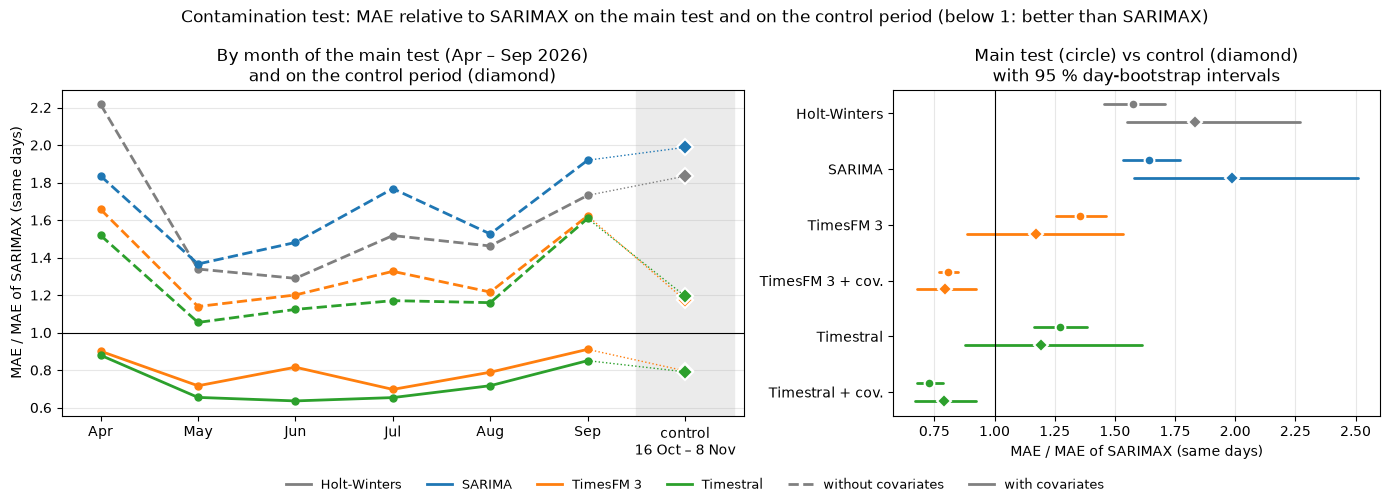

In [ ]:
REL_MODELS = ["holt_winters", "sarima", "timesfm", "timesfm_cov", "timestral", "timestral_cov"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})

# Left: ratio per month (main test) and on the control period
ax = axes[0]
x = np.arange(monthly_rel.shape[1])
for name in REL_MODELS:
    family, with_cov = MODELS[name][1], MODELS[name][2]
    y = monthly_rel.loc[LABELS[name]].to_numpy()
    ax.plot(x[:-1], y[:-1], color=FAMILY_COLORS[family], ls="-" if with_cov else "--", lw=2, marker="o", ms=5)
    ax.plot(x[-1], y[-1], color=FAMILY_COLORS[family], marker="D", ms=8, mec="white", mew=1.5, ls="none")
    ax.plot(x[-2:], y[-2:], color=FAMILY_COLORS[family], ls=":", lw=1)
ax.axhline(1, color="k", lw=0.8)
ax.axvspan(x[-1] - 0.5, x[-1] + 0.5, color="0.92", zorder=0)
ax.set_xticks(x, [*monthly_rel.columns[:-1], "control\n16 Oct – 8 Nov"])
ax.set_xlim(-0.4, x[-1] + 0.6)
ax.set_ylabel("MAE / MAE of SARIMAX (same days)")
ax.set_title("By month of the main test (Apr – Sep 2026)\nand on the control period (diamond)")
ax.grid(axis="y", alpha=0.3)

# Right: main test vs control, with day-bootstrap 95 % intervals
ax = axes[1]
for k, name in enumerate(REL_MODELS):
    family, with_cov = MODELS[name][1], MODELS[name][2]
    for j, (p, marker) in enumerate([("main test", "o"), ("control", "D")]):
        value = contamination.loc[LABELS[name], ("MAE / SARIMAX", p)]
        lo, hi = ci(boot_draws[name][p])
        y = k + (j - 0.5) * 0.32
        ax.plot([lo, hi], [y, y], color=FAMILY_COLORS[family], lw=2, solid_capstyle="round")
        ax.plot(value, y, marker=marker, ms=7, color=FAMILY_COLORS[family], mec="white", mew=1.5, ls="none")
ax.axvline(1, color="k", lw=0.8)
ax.set_yticks(range(len(REL_MODELS)), [LABELS[n] for n in REL_MODELS])
ax.invert_yaxis()
ax.set_xlabel("MAE / MAE of SARIMAX (same days)")
ax.set_title("Main test (circle) vs control (diamond)\nwith 95 % day-bootstrap intervals")
ax.grid(axis="x", alpha=0.3)

handles = [plt.Line2D([], [], color=FAMILY_COLORS[f], lw=2) for f in ["Baseline", "Classical", "TimesFM 3", "Timestral"]]
handles += [plt.Line2D([], [], color="grey", lw=2, ls="--"), plt.Line2D([], [], color="grey", lw=2, ls="-")]
fig.legend(handles, ["Holt-Winters", "SARIMA", "TimesFM 3", "Timestral", "without covariates", "with covariates"],
           loc="lower center", ncol=6, fontsize=9, frameon=False)
fig.suptitle("Contamination test: MAE relative to SARIMAX on the main test and on the control period (below 1: better than SARIMAX)")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(cfg.FIGURES_DIR / "contamination_relative_mae.png", dpi=150)
plt.show()

**Observations.**
- **All models are worse on the control period, and the foundation models are not worse than the others.** The MAE increases by a factor 1.14 to 1.43 for the four foundation models, 1.32 for SARIMAX, 1.54 to 1.60 for Holt-Winters and SARIMA, and about 2.1 for the reference naive and the naive D−7. If the main test had been in the training data of a foundation model, its MAE would have to increase *more* than the MAE of the classical models on unseen data. That is not what happens.
- **Relative to SARIMAX, nothing changes beyond chance.** TimesFM 3 + cov.: 0.81 on the main test, 0.80 on the control period (change 0.99, 95 % interval [0.83, 1.16]). Timestral + cov.: 0.73 → 0.79 (change 1.08, [0.90, 1.29]). The two univariate foundation models even gain ground against SARIMAX on the control period (TimesFM 3 0.86, Timestral 0.94), while SARIMA and Holt-Winters lose ground (1.21 and 1.16). All the intervals of the change contain 1, and they are wide because the control period only has 24 days.
- **The control period looks like an ordinary month.** For every foundation model, its ratio to SARIMAX on the control period falls inside the range of its monthly values on the main test (e.g. Timestral + cov.: 0.64 – 0.85 per month, 0.79 on the control period; TimesFM 3 + cov.: 0.70 – 0.91 per month, 0.80). Inside the main test, the ratio moves from month to month by more than between the main test and the control period (e.g. TimesFM 3: 1.66 in April, 1.14 in May, 1.62 in September; 1.36 on the whole main test, 1.17 on the control period), and the classical models move as much.
- **The month after TimesFM 3's release** (September, which cannot be in its training data) is not clearly different from the months before it: TimesFM 3 + cov. 0.91, against 0.70 – 0.90 from April to August, with Timestral + cov. following the same pattern (0.85 against 0.64 – 0.88).

**Confounders.** The comparison is not a clean experiment, for three reasons:
- **Season**: April – September against mid-October – early November. Prices are higher and less driven by solar in autumn (mean price 179 EUR/MWh from 16 to 31 October and 257 from 1 to 8 November, against 79 to 145 per month from April to September; no hour clearly below 0). The difficulty of the task changes for every model, which is why the comparison uses ratios to models that cannot be contaminated, and the monthly spread.
- **Length**: 24 days against 183. The day-bootstrap intervals show that a change of the ratio by ±15 % on the control period is compatible with chance. The test can detect a large contamination effect, not a small one.
- **DST**: the control period contains the autumn transition (25 October, the repeated hour is averaged, section 5 of the protocol), which the main test does not. It concerns 1 of the 24 days and all models alike.

**Conclusion of the contamination test.** **No contamination signal**: no foundation model is clearly better on the main test than on the control period relative to the models that cannot be contaminated. For TimesFM 3, the model card also lists training data that cannot contain 2026 prices. For Timestral, the documentation does not exclude it (real post-training data and cutoff date not given), but its advantage over SARIMAX remains on data posterior to its release (control ratio 0.79, 95 % interval [0.67, 0.92]). The results of the main test can therefore be read as real zero-shot forecasts, with two limits: the test has low power for a small effect (24 control days), and it relies on the season-adjusted comparison above.

Figure exported to `figures/`: `contamination_relative_mae.png`.

## 6. Diebold-Mariano tests

Are the MAE differences of sections 2 and 3 larger than what chance would produce on 183 days? The **multivariate Diebold-Mariano (DM) test** of `epftoolbox` (Lago et al., 2021), reimplemented in `src/evaluation.py` (`diebold_mariano`, checked against `epftoolbox.evaluation.DM`):

- for each day $t$, the loss differential between models A and B is computed on the **vector of the 24 hourly errors** of the day, $d_t = \frac{1}{24}\sum_h |e_{A,t,h}| - \frac{1}{24}\sum_h |e_{B,t,h}|$ (norm 1, consistent with the MAE, the main metric);
- $DM = \bar d / \sqrt{\hat\sigma^2_d / N}$ over the $N$ days, compared with a standard normal;
- the test is **one-sided**: H0 "B is not more accurate than A", H1 "B is more accurate than A". A small p-value means that **B is significantly better than A**. Since the statistic is normal, the p-value of the other direction is $1 - p$.

Working on daily vectors removes the strong correlation between the 24 hours of a day (they are forecast together, from the same origin), and the daily series $d_t$ of one-day-ahead forecasts needs no autocorrelation correction (as in `epftoolbox`).

**Decisions fixed before computing the tests:**
- significance level **α = 5 %**;
- main test period (183 days) for the conclusions; the control period (24 days) is only reported for consistency;
- norm 1 for the conclusions; norm 2 (squared errors, consistent with the RMSE) as a robustness check, since it gives much more weight to spikes;
- a short list of **planned tests**, which answer the research question, and the full pairwise matrix as a descriptive overview. With 10 models, the matrix holds 90 one-sided tests, so a few p-values below 5 % are expected by chance alone: the conclusions rely on the planned tests, with a Holm correction as a check.

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

from src.evaluation import daily_errors, diebold_mariano

ALPHA = 0.05
# Daily (days × 24) error matrices of every model, per period
errors = {period: {name: daily_errors(r) for name, r in models.items()} for period, models in res.items()}


def dm(period: str, a: str, b: str, norm: int = 1) -> float:
    # p-value of H1 "model b is more accurate than model a"
    return diebold_mariano(errors[period][a], errors[period][b], norm=norm)


best_fm = table.loc[[LABELS[n] for n in FOUNDATION], ("main test", "MAE")].idxmin()
best_fm = next(n for n in FOUNDATION if LABELS[n] == best_fm)
print(f"Best foundation model on the main test (MAE): {LABELS[best_fm]}")

Best foundation model on the main test (MAE): Timestral + cov.


### 6.1 Planned tests

Each line tests H1 "B is more accurate than A":

- **covariates within each family** (the rows of the two-way table): A = version without covariates, B = version with covariates;
- **best foundation model vs SARIMAX**: A = SARIMAX, B = the foundation model with the lowest MAE on the main test;
- **the columns of the two-way table**, as a complement: each foundation model against the classical model with the same information, and TimesFM 3 against Timestral.

When MAE(B) > MAE(A), the line is reported with the arguments swapped, so that B is always the model with the lower MAE on the main test and H1 is the direction suggested by the point estimates.

In [ ]:
PLANNED = {
    "covariates": [("sarima", "sarimax"), ("timesfm", "timesfm_cov"), ("timestral", "timestral_cov")],
    "best foundation vs SARIMAX": [("sarimax", best_fm)],
    "same information (columns)": [("sarima", "timesfm"), ("sarima", "timestral"), ("timesfm", "timestral"),
                                   ("sarimax", "timesfm_cov"), ("sarimax", "timestral_cov"),
                                   ("timesfm_cov", "timestral_cov")],
}


def holm(p: pd.Series) -> pd.Series:
    # Holm-Bonferroni adjusted p-values
    order = p.sort_values()
    adjusted = (order * np.arange(len(order), 0, -1)).cummax().clip(upper=1)
    return adjusted.reindex(p.index)


rows = []
for group, pairs in PLANNED.items():
    for a, b in dict.fromkeys(pairs):  # no duplicate if best_fm is already listed
        main_mae = {n: table.loc[LABELS[n], ("main test", "MAE")] for n in (a, b)}
        if main_mae[b] > main_mae[a]:
            a, b = b, a
        row = {"group": group, "A": LABELS[a], "B (lower MAE)": LABELS[b]}
        for period in PERIODS:
            row[(period, "MAE A")] = table.loc[LABELS[a], (period, "MAE")]
            row[(period, "MAE B")] = table.loc[LABELS[b], (period, "MAE")]
            row[(period, "p (norm 1)")] = dm(period, a, b, norm=1)
            row[(period, "p (norm 2)")] = dm(period, a, b, norm=2)
        rows.append(row)
planned = pd.DataFrame(rows).drop_duplicates(["A", "B (lower MAE)"])
planned = planned.set_index(["group", "A", "B (lower MAE)"])
planned.columns = pd.MultiIndex.from_tuples(planned.columns)
planned[("main test", "Holm p (norm 1)")] = holm(planned[("main test", "p (norm 1)")])
planned = planned[[(p, c) for p in PERIODS for c in ["MAE A", "MAE B", "p (norm 1)", "p (norm 2)", "Holm p (norm 1)"]
                   if (p, c) in planned.columns]]


def fmt_p(p: float) -> str:
    return f"{p:.1e}" if p < 1e-3 else f"{p:.3f}"


def highlight(p: float) -> str:
    return "font-weight: bold" if p < ALPHA else "color: grey"


p_cols = [c for c in planned.columns if c[1].startswith(("p", "Holm"))]
(planned.style
 .format("{:.2f}", subset=[c for c in planned.columns if c[1].startswith("MAE")])
 .format(fmt_p, subset=p_cols)
 .map(highlight, subset=p_cols)
 .set_caption(f"Planned one-sided DM tests, H1: B more accurate than A (bold: p < {ALPHA})"))

### 6.2 Pairwise p-value matrix

All ordered pairs of models on the main test, in the presentation of `epftoolbox` (`plot_multivariate_DM_test`): the cell in row A and column B is the p-value of H1 "**the column model B is more accurate than the row model A**". Green: significant (p close to 0); yellow to red: p between 0.05 and 0.1; black: p ≥ 0.1, not significant. A column with many green cells is a model that is significantly better than many others. Left: norm 1 (absolute errors); right: norm 2 (squared errors).

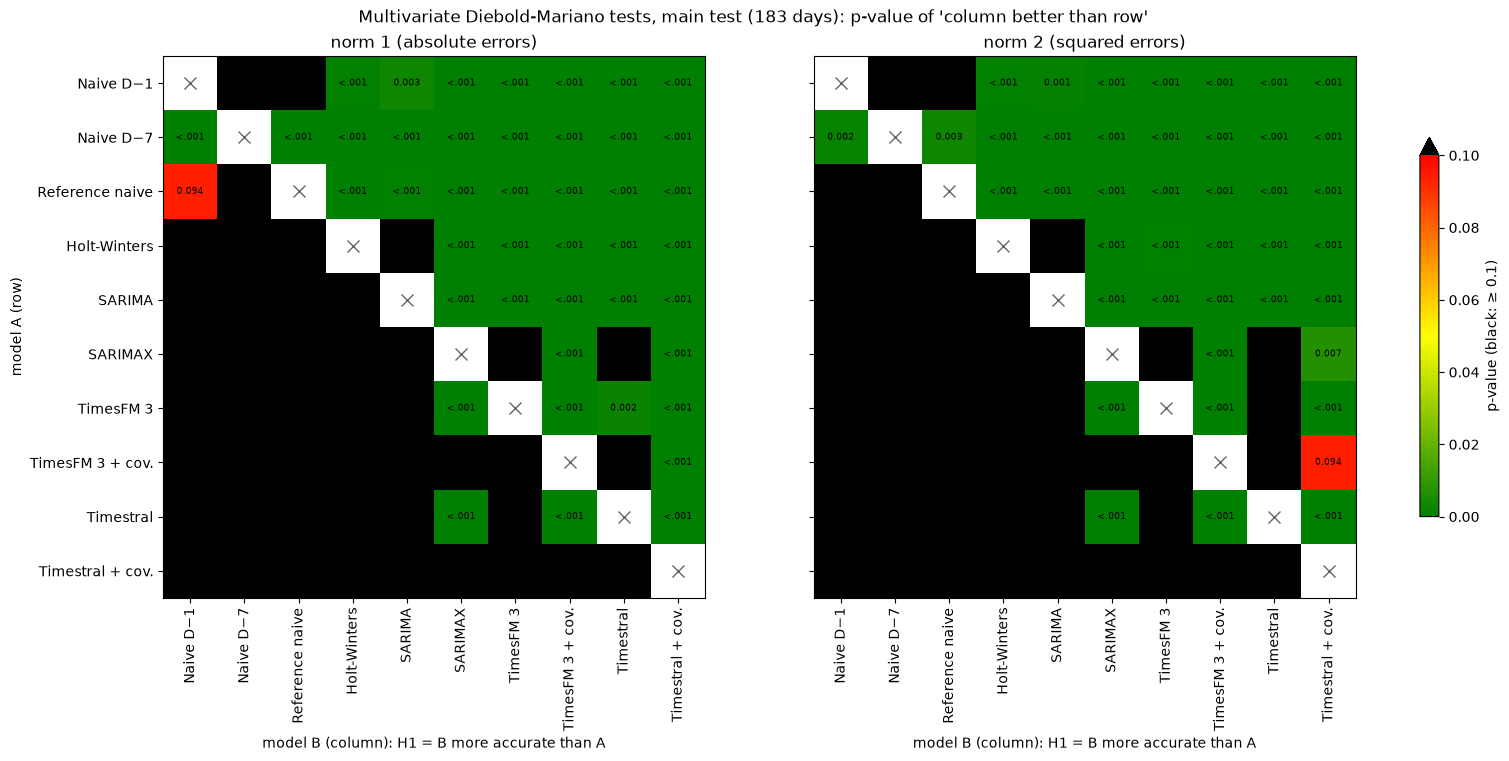

In [ ]:
# Colour scale of epftoolbox: green (p = 0) -> yellow (p = 0.05) -> red (p = 0.1), black above 0.1
DM_CMAP = LinearSegmentedColormap.from_list("dm", [(0, "#008000"), (0.5, "#ffff00"), (1, "#ff0000")])
DM_CMAP.set_over("black")


def p_matrix(period: str, norm: int) -> pd.DataFrame:
    names = list(MODELS)
    return pd.DataFrame([[np.nan if a == b else dm(period, a, b, norm) for b in names] for a in names],
                        index=[LABELS[n] for n in names], columns=[LABELS[n] for n in names])


p_main = {norm: p_matrix("main test", norm) for norm in (1, 2)}

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), sharey=True, layout="constrained")
for ax, (norm, p) in zip(axes, p_main.items()):
    im = ax.imshow(p.to_numpy(), cmap=DM_CMAP, vmin=0, vmax=0.1)
    n = len(p)
    for i in range(n):
        for j in range(n):
            if i == j:
                ax.plot(j, i, "x", color="0.4", ms=8)
                continue
            v = p.iat[i, j]
            text = "<.001" if v < 1e-3 else f"{v:.3f}" if v < 0.1 else ""
            ax.text(j, i, text, ha="center", va="center", fontsize=6.5, color="k")
    ax.set_facecolor("white")
    ax.set_xticks(range(n), p.columns, rotation=90)
    ax.set_yticks(range(n), p.index)
    ax.tick_params(axis="y", labelleft=ax is axes[0])
    ax.set_xlabel("model B (column): H1 = B more accurate than A")
    ax.set_title(f"norm {norm} ({'absolute' if norm == 1 else 'squared'} errors)")
axes[0].set_ylabel("model A (row)")
fig.colorbar(im, ax=axes, extend="max", shrink=0.7, label="p-value (black: ≥ 0.1)")
fig.suptitle("Multivariate Diebold-Mariano tests, main test (183 days): p-value of 'column better than row'")
fig.savefig(cfg.FIGURES_DIR / "dm_pvalues_main_test.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Same matrix on the control period (24 days, norm 1), for reference
p_control = p_matrix("control", 1)
p_control.style.format(lambda v: "–" if np.isnan(v) else fmt_p(v)).map(
    lambda v: "" if np.isnan(v) else highlight(v)).set_caption(
    "Control period, norm 1: p-value of H1 'column more accurate than row' (bold: p < 0.05)")

,Naive D−1,Naive D−7,Reference naive,Holt-Winters,SARIMA,SARIMAX,TimesFM 3,TimesFM 3 + cov.,Timestral,Timestral + cov.
Naive D−1,–,1.000,0.993,0.753,0.891,0.008,0.005,2.2e-04,0.006,1.0e-04
Naive D−7,3.0e-04,–,0.022,1.9e-04,1.8e-04,2.1e-07,1.6e-06,3.9e-08,1.9e-06,3.5e-08
Reference naive,0.007,0.978,–,0.013,0.020,1.0e-04,3.3e-04,3.9e-05,3.7e-04,2.7e-05
Holt-Winters,0.247,1.000,0.987,–,0.746,9.4e-10,2.2e-06,4.1e-17,2.5e-07,3.6e-19
SARIMA,0.109,1.000,0.980,0.254,–,1.2e-06,3.6e-07,3.8e-10,7.2e-05,6.4e-09
SARIMAX,0.992,1.000,1.000,1.000,1.000,–,0.856,0.002,0.868,0.003
TimesFM 3,0.995,1.000,1.000,1.000,1.000,0.144,–,0.002,0.629,0.004
TimesFM 3 + cov.,1.000,1.000,1.000,1.000,1.000,0.998,0.998,–,0.997,0.458
Timestral,0.994,1.000,1.000,1.000,1.000,0.132,0.371,0.003,–,0.002
Timestral + cov.,1.000,1.000,1.000,1.000,1.000,0.997,0.996,0.542,0.998,–


In [ ]:
# Number of models each model beats significantly (norm 1, alpha = 5 %), per period
beats = pd.DataFrame({
    "main test": (p_main[1] < ALPHA).sum(axis=0),
    "control": (p_control < ALPHA).sum(axis=0),
    "beaten by (main test)": (p_main[1] < ALPHA).sum(axis=1),
}).rename_axis("model")
beats

,main test,control,beaten by (main test)
model,,,
Naive D−1,1,2,7
Naive D−7,0,0,9
Reference naive,1,1,7
Holt-Winters,3,2,5
SARIMA,3,2,5
SARIMAX,7,5,2
TimesFM 3,5,5,4
TimesFM 3 + cov.,8,8,1
Timestral,6,5,3


**Observations (α = 5 %, main test, norm 1 unless stated).**

- **Covariates help significantly in every family.** SARIMA → SARIMAX, TimesFM 3 → TimesFM 3 + cov. and Timestral → Timestral + cov. all have p-values below $10^{-28}$ with norm 1 and below $10^{-11}$ with norm 2. The result also holds on the 24 days of the control period (p ≤ 0.004 in the three families, with both norms). The ≈ 40 % MAE reduction of section 3 is not a chance effect.
- **The best foundation model beats SARIMAX significantly.** Timestral + cov. against SARIMAX: p = 1.4e-18 (norm 1), 0.007 (norm 2), 0.003 on the control period. TimesFM 3 + cov. is also significantly better than SARIMAX (p = 1.1e-20 with norm 1, 2.1e-5 with norm 2). In the column "with covariates" of the two-way table, both foundation models are therefore significantly better than the course model.
- **Column "without covariates"**: TimesFM 3 and Timestral are both significantly better than SARIMA, with both norms and on both periods.
- **Across the diagonal**: SARIMAX is significantly better than both univariate foundation models on the main test (matrix: p < 0.001 in the rows TimesFM 3 and Timestral, column SARIMAX). On the control period, the difference is no longer significant (p = 0.14 and 0.13): with 24 days, SARIMAX and the univariate foundation models cannot be separated.
- **TimesFM 3 vs Timestral: the ranking is fragile.** Timestral is significantly better than TimesFM 3 with norm 1 in both columns (p = 0.002 without covariates, 3.4e-4 with), but **not with norm 2** (p = 0.15 and 0.09) and not on the control period (p = 0.63 and 0.46). Timestral is more accurate on typical hours, but not on the large errors, which dominate the squared loss (spikes, deep negative prices, see section 4). The two foundation models should be presented as close, with a small and not robust advantage for Timestral.
- **Holm correction**: the 10 planned tests on the main test remain significant at 5 % with norm 1 after the correction (largest adjusted p-value 0.002). The best foundation model was chosen on the same data as the test, but its p-value against SARIMAX is so small that this selection does not change the conclusion.
- **Matrix, other pairs**: Holt-Winters and SARIMA are **not** significantly different in either direction (p = 0.15 and 0.85); both are significantly better than the three naives. Naive D−1 is not significantly better than the reference naive (p = 0.09). Timestral + cov. is significantly better than all 9 other models, and TimesFM 3 + cov. than 8 (all except Timestral + cov.). Naive D−7 is beaten by all other models.

**Limits of the test.** The DM test compares the expected loss of two models over the period; it assumes a stationary loss differential, while the price volatility changes over the six months (calm and turbulent periods). The p-values are therefore indicative rather than exact, especially for the norm 2, which is dominated by a few spike days. All the conclusions above hold with both norms, except the comparison between TimesFM 3 and Timestral.

Figure exported to `figures/`: `dm_pvalues_main_test.png`.